# 05 — Differential H3K27ac promoters / enhancers and volcanoes

Stage-pair differential accessibility on the 2,635 non-plasma B cells with
H3K27ac. Main-paper **Figure 3** volcano grid.

- Enhancers: Stephanie MERs
- Promoters: TSS −1 kb / +250 bp
- Comparisons: Naive vs GC, GC vs Memory, Memory vs Naive
  (frozen tables store preGC / GC / postGC; `log2FC` = earlier / later)
- Cutoffs: `−log10(padj) > 2` and `|log2FC| > 1`

**Panels below are drawn from the frozen tested tables** in
`paper_results/*_tested_*.tsv`, which match the manuscript volcanoes.
Interval aggregation and `snapatac2.tl.diff_test` are intrinsically
stochastic at the margins; a full recompute can shift a few points. That is
expected. An optional regenerate path is included at the end (commented out).

Plots are display-only (file writes commented out).


In [1]:
%matplotlib inline
import importlib
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

PACKAGE = Path("/mnt/data1/divyanshu/treseq/tonsils/codes/treseq_paper")
if str(PACKAGE.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE.parent))

from treseq_paper import config

importlib.reload(config)

sns.set_theme("talk", style="ticks")
plt.rcParams.update(
    {
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "figure.dpi": 120,
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans"],
        "axes.unicode_minus": False,
    }
)

STAGE_COLOR = dict(config.STAGE_PALETTE)
NS_COLOR = "#BDBDBD"
PADJ_CUT = 1e-2  # -log10(padj) > 2
ABS_LOG2FC_CUT = 1.0
Y_MAX = 50
X_LIM = (-5.2, 5.2)

VOLCANO_PANELS = [
    {
        "title": "Naive vs. GC B-cells",
        "file_pair": "preGC_vs_GC",
        "left": "GC",
        "right": "Naive",
    },
    {
        "title": "GC vs. Memory B-cells",
        "file_pair": "GC_vs_postGC",
        "left": "Memory",
        "right": "GC",
    },
    {
        "title": "Memory vs. Naive B-cells",
        "file_pair": "preGC_vs_postGC",
        "left": "Memory",
        "right": "Naive",
    },
]
ROWS = [
    ("Promoters", "promoters"),
    ("Enhancers", "enhancers"),
]

for kind, files in config.DIFF_TESTED_FILES.items():
    for path in files.values():
        if not path.is_file():
            raise FileNotFoundError(path)


## Frozen tested tables (match the manuscript volcanoes)

Filenames keep the original stage names (`preGC` / `postGC`). Panel titles use
Naive / Memory. `log2_fc` is unchanged (earlier / later as stored).


In [2]:
def load_tested(kind: str, file_pair: str) -> pd.DataFrame:
    path = config.DIFF_TESTED_FILES[kind][file_pair]
    table = pd.read_csv(path, sep="\t")
    for col in ("log2_fc", "padj"):
        if col not in table.columns:
            raise KeyError(f"{path.name} missing {col}")
    if table["log2_fc"].isna().any() or table["padj"].isna().any():
        raise RuntimeError(f"{path.name} has missing log2_fc / padj")
    return table


promoter_results = {}
enhancer_results = {}
census_rows = []
for file_pair in ("preGC_vs_GC", "GC_vs_postGC", "preGC_vs_postGC"):
    promoters = load_tested("promoters", file_pair)
    enhancers = load_tested("enhancers", file_pair)
    promoter_results[file_pair] = promoters
    enhancer_results[file_pair] = enhancers
    census_rows.append(
        {
            "file_pair": file_pair,
            "n_promoters": len(promoters),
            "n_enhancers": len(enhancers),
            "promoter_file": config.DIFF_TESTED_FILES["promoters"][file_pair].name,
            "enhancer_file": config.DIFF_TESTED_FILES["enhancers"][file_pair].name,
        }
    )
display(pd.DataFrame(census_rows))


,file_pair,n_promoters,n_enhancers,promoter_file,enhancer_file
0,preGC_vs_GC,1674,1418,promoter_tested_preGC_vs_GC.tsv,enhancer_tested_preGC_vs_GC.tsv
1,GC_vs_postGC,1648,1419,promoter_tested_GC_vs_postGC.tsv,enhancer_tested_GC_vs_postGC.tsv
2,preGC_vs_postGC,766,1266,promoter_tested_preGC_vs_postGC.tsv,enhancer_tested_preGC_vs_postGC.tsv


## Paper volcano grid


,features,comparison,n_left,left_stage,n_right,right_stage
0,Promoters,Naive vs. GC B-cells,41,GC,36,Naive
1,Promoters,GC vs. Memory B-cells,11,Memory,17,GC
2,Promoters,Memory vs. Naive B-cells,0,Memory,0,Naive
3,Enhancers,Naive vs. GC B-cells,217,GC,60,Naive
4,Enhancers,GC vs. Memory B-cells,55,Memory,167,GC
5,Enhancers,Memory vs. Naive B-cells,26,Memory,8,Naive


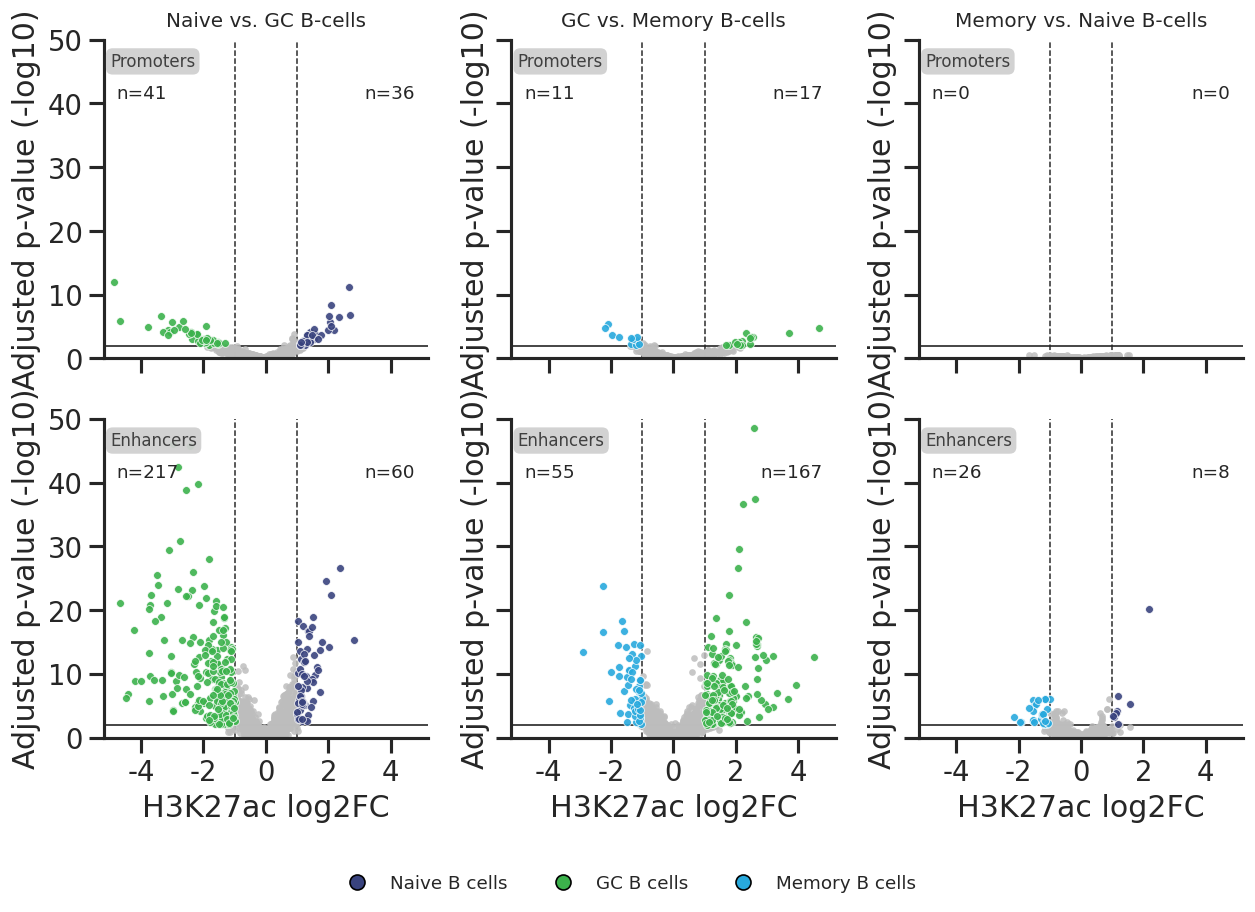

In [3]:
def split_points(fc, y):
    sig = (y > -np.log10(PADJ_CUT)) & (np.abs(fc) > ABS_LOG2FC_CUT)
    left = sig & (fc < -ABS_LOG2FC_CUT)
    right = sig & (fc > ABS_LOG2FC_CUT)
    ns = ~sig
    return ns, left, right


def tag(ax, text):
    ax.text(
        0.02,
        0.96,
        text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        color="0.25",
        bbox={
            "boxstyle": "round,pad=0.25,rounding_size=0.4",
            "facecolor": "#D0D0D0",
            "edgecolor": "none",
            "alpha": 0.95,
        },
        zorder=5,
    )


def draw_volcano(ax, fc, y, left_name, right_name, row_label, show_xlabel, show_ylabel):
    ns, left, right = split_points(fc, y)
    ax.scatter(fc[ns], y[ns], s=16, c=NS_COLOR, linewidths=0, alpha=0.85, zorder=1)
    ax.scatter(
        fc[left],
        y[left],
        s=22,
        c=STAGE_COLOR[left_name],
        edgecolors="white",
        linewidths=0.45,
        alpha=0.9,
        zorder=2,
    )
    ax.scatter(
        fc[right],
        y[right],
        s=22,
        c=STAGE_COLOR[right_name],
        edgecolors="white",
        linewidths=0.45,
        alpha=0.9,
        zorder=2,
    )
    ax.axhline(-np.log10(PADJ_CUT), color="0.15", lw=1.0, ls="-", zorder=0)
    ax.axvline(-ABS_LOG2FC_CUT, color="0.15", lw=0.9, ls="--", zorder=0)
    ax.axvline(ABS_LOG2FC_CUT, color="0.15", lw=0.9, ls="--", zorder=0)
    n_left, n_right = int(left.sum()), int(right.sum())
    ax.text(0.04, 0.86, f"n={n_left}", transform=ax.transAxes, ha="left", va="top", fontsize=11)
    ax.text(0.96, 0.86, f"n={n_right}", transform=ax.transAxes, ha="right", va="top", fontsize=11)
    tag(ax, row_label)
    ax.set_xlim(*X_LIM)
    ax.set_ylim(0, Y_MAX)
    ax.set_xticks([-4, -2, 0, 2, 4])
    ax.set_yticks([0, 10, 20, 30, 40, 50])
    if show_xlabel:
        ax.set_xlabel("H3K27ac log2FC")
    if show_ylabel:
        ax.set_ylabel("Adjusted p-value (-log10)")
    sns.despine(ax=ax)
    return n_left, n_right


result_of = {
    "promoters": promoter_results,
    "enhancers": enhancer_results,
}

fig, axes = plt.subplots(
    len(ROWS), len(VOLCANO_PANELS), figsize=(10.8, 7.6), sharex=True, sharey=True
)
summary_rows = []
for row_i, (row_label, kind) in enumerate(ROWS):
    for col_i, panel in enumerate(VOLCANO_PANELS):
        ax = axes[row_i, col_i]
        table = result_of[kind][panel["file_pair"]]
        fc = table["log2_fc"].astype(float).to_numpy()
        padj = table["padj"].astype(float).to_numpy()
        y = -np.log10(np.clip(padj, 1e-300, 1.0))
        n_left, n_right = draw_volcano(
            ax,
            fc,
            y,
            left_name=panel["left"],
            right_name=panel["right"],
            row_label=row_label,
            show_xlabel=(row_i == len(ROWS) - 1),
            show_ylabel=True,
        )
        if row_i == 0:
            ax.set_title(panel["title"], fontsize=12, pad=8)
        summary_rows.append(
            {
                "features": row_label,
                "comparison": panel["title"],
                "n_left": n_left,
                "left_stage": panel["left"],
                "n_right": n_right,
                "right_stage": panel["right"],
            }
        )

handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=STAGE_COLOR[name],
        markersize=9,
        label=f"{name} B cells",
    )
    for name in ("Naive", "GC", "Memory")
]
fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02),
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
display(pd.DataFrame(summary_rows))
plt.show()
# fig.savefig("volcanoes_promoters_enhancers.pdf", bbox_inches="tight", pad_inches=0.05)  # disabled


## Optional: regenerate the tested tables (commented out)

Uncomment only to recompute interval counts and `snapatac2.tl.diff_test` from
`bcells.h5mu`. Results will be close to the frozen TSVs but are **not
guaranteed to match bit-for-bit**. Use the frozen tables above for
manuscript-identical volcanoes. Stage labels in a recompute use Naive / GC /
Memory; frozen filenames keep preGC / postGC.


In [4]:
# import logging
# import os
# import time
#
# import hdf5plugin
# import anndata as ad
# import muon as mu
# import snapatac2 as snap
# from pybedtools import BedTool
# from scipy import sparse
#
# logging.getLogger("fontTools").setLevel(logging.ERROR)
# os.environ["TQDM_DISABLE"] = "1"
# os.environ["HDF5_PLUGIN_PATH"] = hdf5plugin.PLUGIN_PATH
# os.environ["PATH"] = str(Path(sys.executable).resolve().parent) + os.pathsep + os.environ.get("PATH", "")
#
# BCELLS = config.BCELLS
# STEPHANIE = config.STEPHANIE_MERS
# PROMOTERS_BED = config.PROMOTERS_BED
# CHROM_SIZES = config.CHROM_SIZES
# LABEL = config.CELLTYPE_KEY
# CELLTYPE_SOURCE = config.CELLTYPE_SOURCE_KEY
# B_ORDER = config.B_ORDER
# STAGE_OF = config.STAGE_OF
# PAIRS = [("Naive", "GC"), ("Naive", "Memory"), ("GC", "Memory")]
# MIN_PCT = 0.05
# MIN_LOG_FC = 0.0
# MIN_ABS_LOG2FC = 1.0
# PADJ = 0.05
# STORED_UP = config.STORED_PROMOTER_UPSTREAM
# STORED_DOWN = config.STORED_PROMOTER_DOWNSTREAM
# PROMOTER_UPSTREAM = config.PROMOTER_UPSTREAM
# PROMOTER_DOWNSTREAM = config.PROMOTER_DOWNSTREAM
#
#
# def ensure_celltype(obs):
#     if LABEL in obs.columns:
#         return obs
#     if CELLTYPE_SOURCE not in obs.columns:
#         raise KeyError(f"missing {LABEL} / {CELLTYPE_SOURCE}")
#     return obs.rename(columns={CELLTYPE_SOURCE: LABEL})
#
#
# def ensure_stage(obs):
#     out = obs.copy()
#     mapped = out["stage"].astype(str).replace(config.STAGE_SOURCE_MAP)
#     unknown = sorted(set(mapped) - set(config.STAGE_ORDER))
#     if unknown:
#         raise RuntimeError(f"unexpected stage labels: {unknown}")
#     out["stage"] = pd.Categorical(mapped, categories=config.STAGE_ORDER)
#     return out
#
#
# def bin_table(var_names):
#     names = pd.Index(var_names).astype(str)
#     span = names.str.split(":", n=1).str[1].str.split("-", n=1)
#     table = pd.DataFrame(
#         {
#             "chrom": names.str.split(":", n=1).str[0].to_numpy(),
#             "start": span.str[0].astype(int).to_numpy(),
#             "end": span.str[1].astype(int).to_numpy(),
#             "tile_ix": np.arange(len(names)),
#         }
#     )
#     if not np.all((table["end"] - table["start"]).to_numpy() == 1000):
#         raise RuntimeError("H3K27ac tiles are not all 1 kb")
#     return table
#
#
# def transcription_starts(path):
#     bed = pd.read_csv(
#         path, sep="\t", header=None,
#         names=["chrom", "start", "end", "name", "score", "strand"],
#     )
#     width = STORED_UP + STORED_DOWN
#     if not np.all((bed["end"] - bed["start"]).to_numpy() == width):
#         raise RuntimeError(f"Promoter annotation intervals are not all {width} bp")
#     plus = bed["strand"].eq("+").to_numpy()
#     tss = np.where(plus, bed["start"] + STORED_UP, bed["end"] - STORED_UP)
#     gene = bed["name"].str.replace(r"_\d+$", "", regex=True)
#     return pd.DataFrame(
#         {"chrom": bed["chrom"].to_numpy(), "tss": tss.astype(int), "gene": gene.to_numpy()}
#     ).sort_values(["chrom", "tss"]).reset_index(drop=True)
#
#
# def nearest_gene(enhancers, starts):
#     by_chrom = {
#         chrom: (sub["tss"].to_numpy(dtype=int), sub["gene"].to_numpy())
#         for chrom, sub in starts.groupby("chrom", sort=False)
#     }
#     genes, distances = [], []
#     for chrom, start, end in zip(enhancers["chrom"], enhancers["start"], enhancers["end"]):
#         pos, names = by_chrom[chrom]
#         start, end = int(start), int(end)
#         left = int(np.searchsorted(pos, start, side="left"))
#         right = int(np.searchsorted(pos, end, side="left"))
#         if right > left:
#             center = (start + end) / 2
#             order = np.argsort(np.abs(pos[left:right] - center))
#             genes.append(", ".join(names[left:right][order]))
#             distances.append(0)
#             continue
#         candidates = []
#         if left > 0:
#             candidates.append((start - int(pos[left - 1]), names[left - 1]))
#         if left < len(pos):
#             candidates.append((int(pos[left]) - end, names[left]))
#         distance, gene = min(candidates, key=lambda item: item[0])
#         genes.append(str(gene))
#         distances.append(int(distance))
#     out = enhancers.copy()
#     out["gene"] = genes
#     out["distance"] = distances
#     return out
#
#
# def promoter_intervals(path):
#     bed = pd.read_csv(
#         path, sep="\t", header=None,
#         names=["chrom", "start", "end", "name", "score", "strand"],
#     )
#     gene = bed["name"].str.replace(r"_\d+$", "", regex=True)
#     plus = bed["strand"].eq("+").to_numpy()
#     tss = np.where(plus, bed["start"] + STORED_UP, bed["end"] - STORED_UP)
#     start = np.where(plus, tss - PROMOTER_UPSTREAM, tss - PROMOTER_DOWNSTREAM).astype(int)
#     end = np.where(plus, tss + PROMOTER_DOWNSTREAM, tss + PROMOTER_UPSTREAM).astype(int)
#     sizes = pd.read_csv(CHROM_SIZES, sep="\t", header=None, names=["chrom", "size"])
#     size_of = dict(zip(sizes["chrom"], sizes["size"].astype(int)))
#     chrom_size = bed["chrom"].map(size_of).to_numpy()
#     start = np.clip(start, 0, chrom_size)
#     end = np.clip(end, 0, chrom_size)
#     out = pd.DataFrame(
#         {
#             "chrom": bed["chrom"].to_numpy(),
#             "start": start,
#             "end": end,
#             "name": bed["name"].to_numpy(),
#             "strand": bed["strand"].to_numpy(),
#             "gene": gene.to_numpy(),
#         }
#     ).sort_values(["chrom", "start", "end", "gene"]).reset_index(drop=True)
#     out["kb"] = (out["end"] - out["start"]) / 1000
#     return out
#
#
# def stage_index(stage):
#     return np.flatnonzero(ac.obs["stage"].astype(str).to_numpy() == stage)
#
#
# def diff_test_pair(adata, names, stage_a, stage_b):
#     ix_a = stage_index(stage_a)
#     ix_b = stage_index(stage_b)
#     raw = snap.tl.diff_test(
#         adata,
#         ix_a.tolist(),
#         ix_b.tolist(),
#         direction="both",
#         min_log_fc=MIN_LOG_FC,
#         min_pct=MIN_PCT,
#     )
#     table = raw.to_pandas().set_index("feature name")
#     names = pd.Index(names).astype(str)
#     keep = np.asarray(names.isin(table.index))
#     log2_fc = np.full(len(names), np.nan)
#     pvalue = np.full(len(names), np.nan)
#     padj = np.full(len(names), np.nan)
#     ordered = table.loc[names[keep]]
#     log2_fc[keep] = ordered["log2(fold_change)"].to_numpy()
#     pvalue[keep] = ordered["p-value"].to_numpy()
#     padj[keep] = ordered["adjusted p-value"].to_numpy()
#     return ix_a, ix_b, keep, log2_fc, pvalue, padj
#
#
# mdata = mu.read_h5mu(BCELLS)
# ac = mdata.mod["H3K27ac"]
# ac.obs = ensure_stage(ensure_celltype(ac.obs))
# if not sparse.isspmatrix_csr(ac.X):
#     ac.X = sparse.csr_matrix(ac.X)
# tiles = bin_table(ac.var_names)
# tile_bed = BedTool.from_dataframe(tiles[["chrom", "start", "end", "tile_ix"]]).sort()
# library = np.asarray(ac.X.sum(axis=1)).ravel().astype(np.float64)
#
# enhancers = pd.read_csv(
#     STEPHANIE, sep="\t", header=None, names=["chrom", "start", "end", "name", "score"]
# ).sort_values(["chrom", "start", "end"]).reset_index(drop=True)
# starts = transcription_starts(PROMOTERS_BED)
# enhancer_bed = BedTool.from_dataframe(
#     enhancers.reset_index()[["chrom", "start", "end", "index"]]
# ).sort()
# hits = tile_bed.intersect(enhancer_bed, wa=True, wb=True).to_dataframe(
#     disable_auto_names=True,
#     names=["t_chrom", "t_start", "t_end", "tile_ix", "e_chrom", "e_start", "e_end", "enhancer_ix"],
# )
# pairs = hits[["tile_ix", "enhancer_ix"]].drop_duplicates()
# indicator = sparse.csr_matrix(
#     (np.ones(len(pairs)), (pairs["tile_ix"], pairs["enhancer_ix"])),
#     shape=(ac.n_vars, len(enhancers)),
# )
# n_tiles = np.asarray(indicator.sum(axis=0)).ravel().astype(int)
# counts = (ac.X @ indicator).toarray()
# cell_cpm = counts / library[:, None] * 1e6
# enhancers = nearest_gene(enhancers, starts)
# enhancers["n_tiles"] = n_tiles
# enhancers["kb"] = (enhancers["end"] - enhancers["start"]) / 1000
# enh_adata = ad.AnnData(X=sparse.csr_matrix(counts), obs=ac.obs[["stage"]].copy())
# enh_adata.var_names = pd.Index(enhancers["name"].astype(str))
#
# promoters = promoter_intervals(PROMOTERS_BED)
# promoter_bed = BedTool.from_dataframe(
#     promoters.reset_index()[["chrom", "start", "end", "index"]]
# ).sort()
# promoter_hits = tile_bed.intersect(promoter_bed, wa=True, wb=True).to_dataframe(
#     disable_auto_names=True,
#     names=["t_chrom", "t_start", "t_end", "tile_ix", "p_chrom", "p_start", "p_end", "promoter_ix"],
# )
# promoter_pairs = promoter_hits[["tile_ix", "promoter_ix"]].drop_duplicates()
# promoter_indicator = sparse.csr_matrix(
#     (np.ones(len(promoter_pairs)), (promoter_pairs["tile_ix"], promoter_pairs["promoter_ix"])),
#     shape=(ac.n_vars, len(promoters)),
# )
# promoters["n_tiles"] = np.asarray(promoter_indicator.sum(axis=0)).ravel().astype(int)
# promoter_counts = (ac.X @ promoter_indicator).toarray()
# promoter_cpm = promoter_counts / library[:, None] * 1e6
# promoter_adata = ad.AnnData(X=sparse.csr_matrix(promoter_counts), obs=ac.obs[["stage"]].copy())
# promoter_adata.var_names = pd.Index(promoters["gene"].astype(str))
#
# # Then for each (stage_a, stage_b) in PAIRS call snap.tl.diff_test via
# # diff_test_pair(...), assemble tested tables with log2_fc / padj / pct / cpm,
# # and feed the same draw_volcano grid. TSV writes stay commented out.
